In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
import os
data_path = 'BankChurners.csv' if os.path.exists('BankChurners.csv') else '/content/BankChurners.csv'
df = pd.read_csv(data_path)
df.head()


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [49]:
df.shape

(10127, 23)

In [50]:
!pip install -U ydata-profiling

In [51]:
from pandas_profiling import ProfileReport
prof = ProfileReport (df)
prof.to_file(output_file=' output.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 23/23 [00:00<00:00, 29.09it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [53]:
df = df.drop(columns=df.filter(like="Naive_Bayes_Classifier").columns)

In [54]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  object 
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  object 
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           10127 non-null  object 
 6   Marital_Status            10127 non-null  object 
 7   Income_Category           10127 non-null  object 
 8   Card_Category             10127 non-null  object 
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_

In [56]:
df.tail(5)

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,...,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,...,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,...,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,...,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,...,2,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189


In [57]:
for col in df.columns:
    print(df[col].value_counts())

CLIENTNUM
714337233    1
768805383    1
818770008    1
713982108    1
769911858    1
            ..
709327383    1
806160108    1
753327333    1
709967358    1
714885258    1
Name: count, Length: 10127, dtype: int64
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64
Customer_Age
44    500
49    495
46    490
45    486
47    479
43    473
48    472
50    452
42    426
51    398
53    387
41    379
52    376
40    361
39    333
54    307
38    303
55    279
56    262
37    260
57    223
36    221
35    184
58    157
59    157
34    146
60    127
33    127
32    106
65    101
61     93
62     93
31     91
26     78
30     70
63     65
29     56
64     43
27     32
28     29
67      4
66      2
68      2
70      1
73      1
Name: count, dtype: int64
Gender
F    5358
M    4769
Name: count, dtype: int64
Dependent_count
3    2732
2    2655
1    1838
4    1574
0     904
5     424
Name: count, dtype: int64
Education_Level
Graduate         3128
High Scho

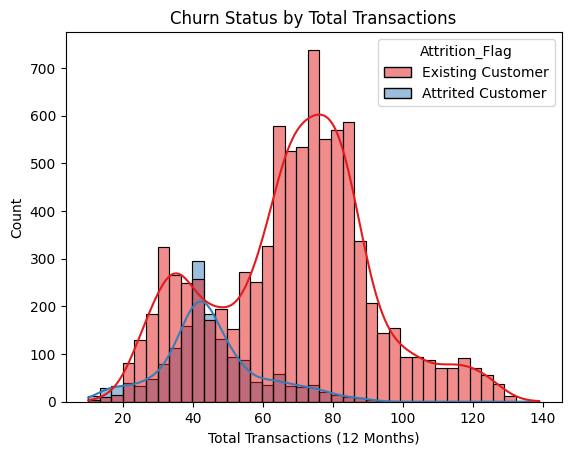

In [58]:
sns.histplot(data=df, x="Total_Trans_Ct", hue="Attrition_Flag", kde=True, palette="Set1")
plt.title("Churn Status by Total Transactions")
plt.xlabel("Total Transactions (12 Months)")
plt.show()

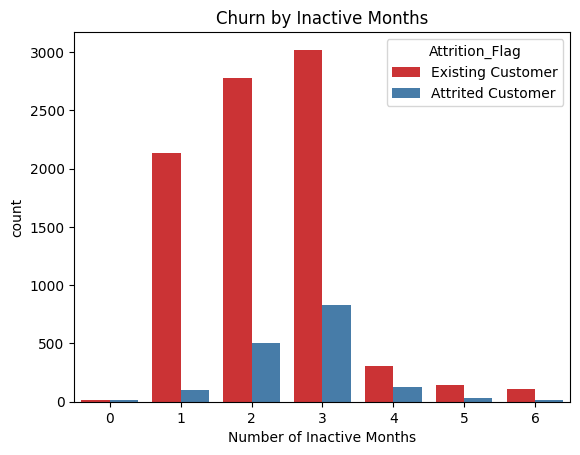

In [59]:
sns.countplot(data=df, x="Months_Inactive_12_mon", hue="Attrition_Flag", palette="Set1")
plt.title("Churn by Inactive Months")
plt.xlabel("Number of Inactive Months")
plt.show()

/tmp/ipykernel_2969/3343597416.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Attrition_Flag", y="Avg_Open_To_Buy", palette="Set2")


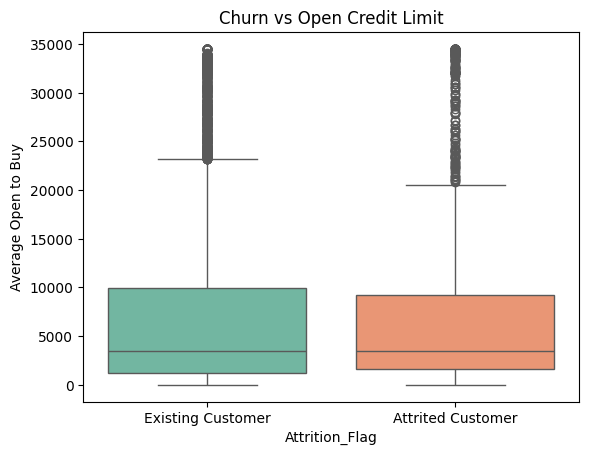

In [60]:
sns.boxplot(data=df, x="Attrition_Flag", y="Avg_Open_To_Buy", palette="Set2")
plt.title("Churn vs Open Credit Limit")
plt.ylabel("Average Open to Buy")
plt.show()

In [61]:
from sklearn.model_selection import train_test_split

In [62]:
X = df.drop(columns=["Attrition_Flag", "CLIENTNUM"])
y = df["Attrition_Flag"]

In [63]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=15)

In [64]:
X_train.shape

(7088, 19)

In [65]:
df["Income_Category"].unique()

array(['$60K - $80K', 'Less than $40K', '$80K - $120K', '$40K - $60K',
       '$120K +', 'Unknown'], dtype=object)

In [66]:
df["Card_Category"].unique()

array(['Blue', 'Gold', 'Silver', 'Platinum'], dtype=object)

In [67]:
df["Education_Level"].unique()

array(['High School', 'Graduate', 'Uneducated', 'Unknown', 'College',
       'Post-Graduate', 'Doctorate'], dtype=object)

In [68]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [69]:
hierarchy_cols = ["Income_Category", "Card_Category", "Education_Level"]
nominal_cols = ["Gender", "Marital_Status"]

ordinal_encoder = OrdinalEncoder(categories=[
    ['Unknown', 'Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +'],
    ['Blue', 'Silver', 'Gold', 'Platinum'],
    ['Unknown', 'Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate']
])

onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer([
    ("ordinal", ordinal_encoder, hierarchy_cols),
    ("onehot", onehot_encoder, nominal_cols)
], remainder='passthrough')

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [70]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

In [71]:
tree_model = DecisionTreeClassifier(criterion = "gini", max_depth =3, random_state = 0)

tree_model.fit(X_train_transformed,y_train)

DecisionTreeClassifier(max_depth=3, random_state=0)

In [72]:
y_pred = tree_model.predict(X_test_transformed)

In [73]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [74]:
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9157617637380717
[[ 337  152]
 [ 104 2446]]
                   precision    recall  f1-score   support

Attrited Customer       0.76      0.69      0.72       489
Existing Customer       0.94      0.96      0.95      2550

         accuracy                           0.92      3039
        macro avg       0.85      0.82      0.84      3039
     weighted avg       0.91      0.92      0.91      3039



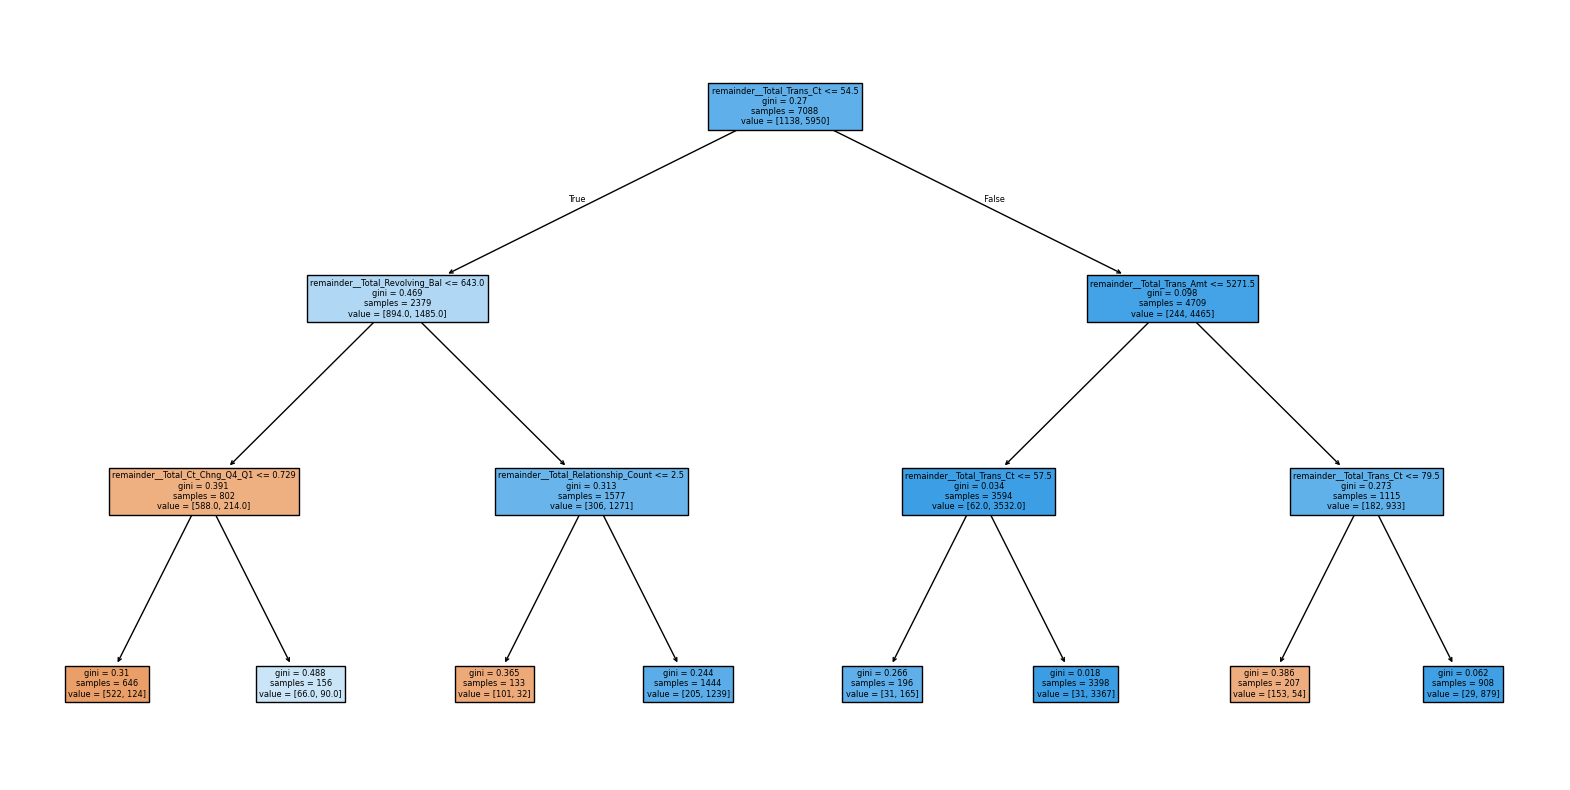

In [75]:
from sklearn import tree

column_names = preprocessor.get_feature_names_out()
plt.figure(figsize=(20, 10))
tree.plot_tree(
    tree_model,
    feature_names=column_names,
    filled=True
)
plt.show()

In [76]:
param = {
    "criterion" : ["gini", "entropy", "log_loss"],
    "splitter" : ["best", "random"],
    "max_depth" : [1,2,3,4,5,15,None],
    "max_features" : ["sqrt", "log2", None]
}

In [77]:
from sklearn.model_selection import GridSearchCV

In [78]:
grid = GridSearchCV(estimator = DecisionTreeClassifier(), param_grid=param, cv=5,scoring="accuracy")

In [79]:
grid.fit(X_train_transformed, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [1, 2, 3, 4, 5, 15, None],
                         'max_features': ['sqrt', 'log2', None],
                         'splitter': ['best', 'random']},
             scoring='accuracy')

In [80]:
grid.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'splitter': 'best'}

In [81]:
y_pred = grid.predict(X_test_transformed)

In [82]:
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9430733794011188
[[ 402   87]
 [  86 2464]]
                   precision    recall  f1-score   support

Attrited Customer       0.82      0.82      0.82       489
Existing Customer       0.97      0.97      0.97      2550

         accuracy                           0.94      3039
        macro avg       0.89      0.89      0.89      3039
     weighted avg       0.94      0.94      0.94      3039



In [83]:
tree_model_new = DecisionTreeClassifier(criterion="entropy",max_depth=15, max_features=None, splitter="best")

In [84]:
tree_model_new.fit(X_train_transformed, y_train)
y_pred = tree_model_new.predict(X_test_transformed)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9430733794011188
[[ 409   80]
 [  93 2457]]
                   precision    recall  f1-score   support

Attrited Customer       0.81      0.84      0.83       489
Existing Customer       0.97      0.96      0.97      2550

         accuracy                           0.94      3039
        macro avg       0.89      0.90      0.90      3039
     weighted avg       0.94      0.94      0.94      3039



[Text(0.53951126998002, 0.96875, 'remainder__Total_Trans_Ct <= 56.5\nentropy = 0.636\nsamples = 7088\nvalue = [1138, 5950]'),
 Text(0.23449207042957043, 0.90625, 'remainder__Total_Revolving_Bal <= 628.5\nentropy = 0.948\nsamples = 2511\nvalue = [919.0, 1592.0]'),
 Text(0.3870016702047952, 0.9375, 'True  '),
 Text(0.07851523476523477, 0.84375, 'remainder__Total_Relationship_Count <= 2.5\nentropy = 0.862\nsamples = 838\nvalue = [599.0, 239.0]'),
 Text(0.007992007992007992, 0.78125, 'remainder__Credit_Limit <= 13455.0\nentropy = 0.117\nsamples = 191\nvalue = [188, 3]'),
 Text(0.003996003996003996, 0.71875, 'entropy = 0.0\nsamples = 152\nvalue = [152, 0]'),
 Text(0.011988011988011988, 0.71875, 'remainder__Total_Amt_Chng_Q4_Q1 <= 0.775\nentropy = 0.391\nsamples = 39\nvalue = [36, 3]'),
 Text(0.007992007992007992, 0.65625, 'entropy = 0.0\nsamples = 26\nvalue = [26, 0]'),
 Text(0.015984015984015984, 0.65625, 'remainder__Months_on_book <= 35.0\nentropy = 0.779\nsamples = 13\nvalue = [10, 3]'),

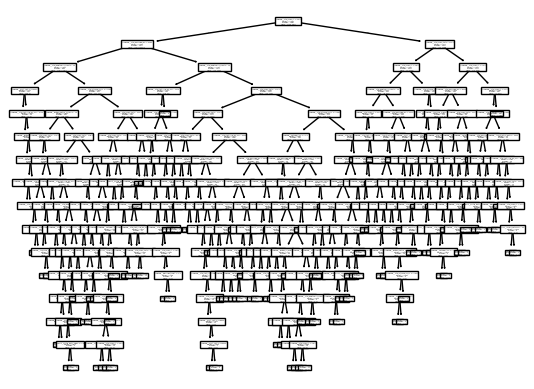

In [85]:
tree.plot_tree(tree_model_new.fit(X_train_transformed, y_train),feature_names=column_names)

In [88]:
print(df.columns.tolist())

['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


In [89]:
X_reg = df.drop(
    columns=['Credit_Limit', 'Avg_Open_To_Buy', 'CLIENTNUM']
)

y_reg = df['Credit_Limit']

In [90]:
nominal_cols_reg = ["Gender", "Marital_Status", "Attrition_Flag"]
preprocessor_reg = ColumnTransformer(
    transformers=[
        ("ordinal_donusum", ordinal_encoder, hierarchy_cols),
        ("onehot_donusum", OneHotEncoder(drop='first', sparse_output=False), nominal_cols_reg)
    ],
    remainder="passthrough"
)

In [91]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [92]:
X_train_reg_transformed = preprocessor_reg.fit_transform(X_train_reg)
X_test_reg_transformed = preprocessor_reg.transform(X_test_reg)

In [93]:
reg_model = DecisionTreeRegressor(random_state=42)
reg_model.fit(X_train_reg_transformed, y_train_reg)

DecisionTreeRegressor(random_state=42)

In [94]:
y_pred_reg = reg_model.predict(X_test_reg_transformed)

In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [96]:
print("R2: ", r2_score(y_test_reg, y_pred_reg))
print("MAE: ", mean_absolute_error(y_test_reg, y_pred_reg))
print("MSE: ", mean_squared_error(y_test_reg,y_pred_reg))

R2:  0.7755248311499551
MAE:  1593.411204343534
MSE:  18581317.54124877


In [97]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.8 MB/s eta 0:00:00


In [98]:
import optuna

In [99]:
def objective(trial):
    param = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
        "random_state": 42
    }
    model = DecisionTreeRegressor(**param)
    model.fit(X_train_reg_transformed, y_train_reg)
    preds = model.predict(X_test_reg_transformed)
    rmse = np.sqrt(mean_squared_error(y_test_reg, preds))
    return rmse

In [100]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

[I 2026-10-18 04:38:47,489] A new study created in memory with name: no-name-be5ff089-0da0-4483-b724-65f55dfff482
[I 2026-10-18 04:38:47,572] Trial 0 finished with value: 3413.668174549346 and parameters: {'max_depth': 8, 'min_samples_split': 43, 'min_samples_leaf': 2}. Best is trial 0 with value: 3413.668174549346.
[I 2026-10-18 04:38:47,615] Trial 1 finished with value: 3978.5661496617636 and parameters: {'max_depth': 5, 'min_samples_split': 21, 'min_samples_leaf': 8}. Best is trial 0 with value: 3413.668174549346.
[I 2026-10-18 04:38:47,693] Trial 2 finished with value: 3422.284792523 and parameters: {'max_depth': 8, 'min_samples_split': 48, 'min_samples_leaf': 2}. Best is trial 0 with value: 3413.668174549346.
[I 2026-10-18 04:38:47,766] Trial 3 finished with value: 3551.406257578506 and parameters: {'max_depth': 10, 'min_samples_split': 19, 'min_samples_leaf': 30}. Best is trial 0 with value: 3413.668174549346.
[I 2026-10-18 04:38:47,880] Trial 4 finished with value: 3633.05176362

In [101]:
study.best_params

{'max_depth': 9, 'min_samples_split': 8, 'min_samples_leaf': 2}

In [102]:
best_params = study.best_params
best_params["random_state"] = 42
final_reg_model = DecisionTreeRegressor(**best_params)
final_reg_model.fit(X_train_reg_transformed, y_train_reg)

DecisionTreeRegressor(max_depth=9, min_samples_leaf=2, min_samples_split=8,
                      random_state=42)

In [103]:
final_preds = final_reg_model.predict(X_test_reg_transformed)
print("R2: " ,r2_score(y_test_reg, final_preds))

R2:  0.8761867116833778


In [104]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

In [105]:
X_train_transformed = preprocessor_reg.fit_transform(X_train_reg)

X_test_transformed = preprocessor_reg.transform(X_test_reg)

In [106]:
print(X_train_transformed.shape)
print(y_train_reg.shape)

print(X_test_transformed.shape)
print(y_test_reg.shape)

(8101, 20)
(8101,)
(2026, 20)
(2026,)


In [107]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd


models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
}


results = []

for name, model in models.items():

    model.fit(X_train_transformed, y_train_reg)

    y_pred = model.predict(X_test_transformed)

    r2 = r2_score(y_test_reg, y_pred)
    mae = mean_absolute_error(y_test_reg, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred))

    results.append([name, r2, mae, rmse])


results_df = pd.DataFrame(
    results,
    columns=["Model", "R2 Score", "MAE", "RMSE"]
)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

print(results_df.to_string(index=False))


best_model_name = results_df.iloc[0]["Model"]

print("\nBest Model:", best_model_name)

            Model  R2 Score         MAE        RMSE
          XGBoost  0.901313 1219.983143 2858.141016
      Extra Trees  0.893480 1130.561746 2969.401236
    Random Forest  0.890066 1140.377953 3016.612494
Gradient Boosting  0.881705 1586.653091 3129.223649
    Decision Tree  0.775525 1593.411204 4310.605241
Linear Regression  0.593725 4170.564862 5799.147949
 Lasso Regression  0.593725 4170.559404 5799.150114
 Ridge Regression  0.593698 4168.860256 5799.341773

Best Model: XGBoost


In [108]:
import optuna
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

def objective(trial):

    model = XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_alpha=trial.suggest_float("reg_alpha", 0, 10),
        reg_lambda=trial.suggest_float("reg_lambda", 0, 10),
        random_state=42
    )

    model.fit(X_train_transformed, y_train_reg)

    y_pred = model.predict(X_test_transformed)

    return r2_score(y_test_reg, y_pred)


study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=50)

print("Best R2:", study.best_value)
print("Best Parameters:", study.best_params)

[I 2026-10-18 04:39:42,714] A new study created in memory with name: no-name-f6876515-3c97-41e0-924a-ffbc9d1d194c
[I 2026-10-18 04:39:42,876] Trial 0 finished with value: 0.8885653709217785 and parameters: {'n_estimators': 130, 'max_depth': 5, 'learning_rate': 0.02755478339303205, 'subsample': 0.8328092401023165, 'colsample_bytree': 0.8223265234389404, 'min_child_weight': 1, 'reg_alpha': 7.669331425768371, 'reg_lambda': 7.1290937514490205}. Best is trial 0 with value: 0.8885653709217785.
[I 2026-10-18 04:39:43,186] Trial 1 finished with value: 0.8944989057814091 and parameters: {'n_estimators': 209, 'max_depth': 6, 'learning_rate': 0.083813477985546, 'subsample': 0.7038487338465429, 'colsample_bytree': 0.8957203767979662, 'min_child_weight': 3, 'reg_alpha': 9.907949581106163, 'reg_lambda': 0.13521711498610922}. Best is trial 1 with value: 0.8944989057814091.
[I 2026-10-18 04:39:44,491] Trial 2 finished with value: 0.8812622895792424 and parameters: {'n_estimators': 203, 'max_depth': 10

Best R2: 0.8997998253438994
Best Parameters: {'n_estimators': 238, 'max_depth': 5, 'learning_rate': 0.1608726902360878, 'subsample': 0.9992146320061833, 'colsample_bytree': 0.6509630632464142, 'min_child_weight': 7, 'reg_alpha': 8.763803816554358, 'reg_lambda': 3.6283752541719307}


In [109]:
df["Avg_Utilization_Ratio"] = (
    df["Total_Revolving_Bal"] / df["Credit_Limit"]
)

In [110]:
df["Credit_Limit"].describe()

,Credit_Limit
count,10127.000000
mean,8631.953698
std,9088.776650
min,1438.300000
25%,2555.000000
50%,4549.000000
75%,11067.500000
max,34516.000000


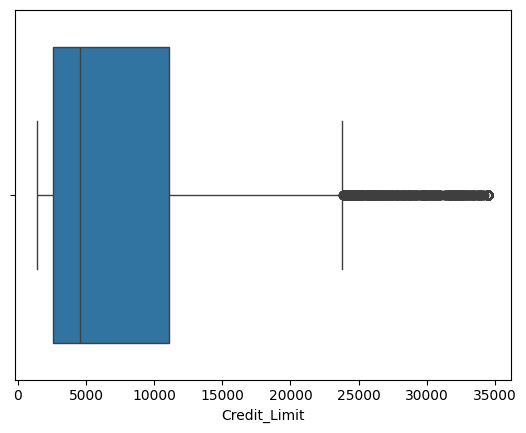

In [111]:
sns.boxplot(x=df["Credit_Limit"])
plt.show()

In [112]:
best_params = {
    'n_estimators': 383,
    'max_depth': 6,
    'learning_rate': 0.028656575474493153,
    'subsample': 0.9694994488523009,
    'colsample_bytree': 0.9717696667130956,
    'min_child_weight': 4,
    'reg_alpha': 3.985646109943311,
    'reg_lambda': 0.9818698213269912
}

final_model = XGBRegressor(
    **best_params,
    random_state=42
)

final_model.fit(X_train_transformed, y_train_reg)

y_pred = final_model.predict(X_test_transformed)

print("R2 Score:", r2_score(y_test_reg, y_pred))
print("MAE:", mean_absolute_error(y_test_reg, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, y_pred)))

R2 Score: 0.9024523687443904
MAE: 1139.7716595483087
RMSE: 2841.596852711742


In [113]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    final_model,
    X_train_transformed,
    y_train_reg,
    cv=5,
    scoring="r2"
)

print("CV Scores:", scores)
print("Mean CV R2:", scores.mean())

CV Scores: [0.88404781 0.88118546 0.88750825 0.89013669 0.89927916]
Mean CV R2: 0.8884314732322401


In [114]:
# ==============================
# 1. Prepare X and y
# ==============================

X = df.drop(columns=["Attrition_Flag", "CLIENTNUM"])

y = df["Attrition_Flag"].map({
    "Existing Customer": 0,
    "Attrited Customer": 1
})


# ==============================
# 2. Train-Test Split
# ==============================

from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=15,
    stratify=y
)


# ==============================
# 3. Preprocessing
# ==============================

X_train_cls_transformed = preprocessor.fit_transform(X_train_cls)

X_test_cls_transformed = preprocessor.transform(X_test_cls)


# ==============================
# 4. Models
# ==============================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd


models = {

    "Logistic Regression": LogisticRegression(
        max_iter=3000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric="logloss"
    )
}


# ==============================
# 5. Model Comparison
# ==============================

results = []

for name, model in models.items():

    model.fit(
        X_train_cls_transformed,
        y_train_cls
    )

    y_pred = model.predict(
        X_test_cls_transformed
    )

    y_prob = model.predict_proba(
        X_test_cls_transformed
    )[:, 1]

    accuracy = accuracy_score(
        y_test_cls,
        y_pred
    )

    precision = precision_score(
        y_test_cls,
        y_pred,
        pos_label=1
    )

    recall = recall_score(
        y_test_cls,
        y_pred,
        pos_label=1
    )

    f1 = f1_score(
        y_test_cls,
        y_pred,
        pos_label=1
    )

    roc_auc = roc_auc_score(
        y_test_cls,
        y_prob
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ])


# ==============================
# 6. Results
# ==============================

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
)


results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)


print(results_df.to_string(index=False))


# ==============================
# 7. Best Model
# ==============================

best_model_name = results_df.iloc[0]["Model"]

print("\n🏆 Best Model:", best_model_name)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
            XGBoost  0.971372   0.942605 0.875000  0.907545 0.992227
  Gradient Boosting  0.963804   0.954327 0.813525  0.878319 0.988159
      Random Forest  0.961171   0.953431 0.797131  0.868304 0.985746
      Decision Tree  0.941099   0.835141 0.788934  0.811380 0.879571
        Extra Trees  0.935834   0.942598 0.639344  0.761905 0.980102
Logistic Regression  0.903258   0.790419 0.540984  0.642336 0.915831

🏆 Best Model: XGBoost


In [115]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import f1_score


def objective(trial):

    model = XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float(
            "learning_rate", 0.01, 0.3
        ),
        subsample=trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        colsample_bytree=trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        min_child_weight=trial.suggest_int(
            "min_child_weight", 1, 10
        ),
        gamma=trial.suggest_float(
            "gamma", 0, 5
        ),
        reg_alpha=trial.suggest_float(
            "reg_alpha", 0, 10
        ),
        reg_lambda=trial.suggest_float(
            "reg_lambda", 0, 10
        ),
        random_state=42,
        eval_metric="logloss"
    )

    model.fit(
        X_train_cls_transformed,
        y_train_cls
    )

    y_pred = model.predict(
        X_test_cls_transformed
    )

    return f1_score(
        y_test_cls,
        y_pred
    )


study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=50
)


print("Best F1 Score:", study.best_value)

print("\nBest Parameters:")
print(study.best_params)

[I 2026-10-18 04:40:55,950] A new study created in memory with name: no-name-72813b71-64e1-4293-9d95-f399380ac2e6
[I 2026-10-18 04:40:56,094] Trial 0 finished with value: 0.8818380743982495 and parameters: {'n_estimators': 218, 'max_depth': 3, 'learning_rate': 0.05029923816265283, 'subsample': 0.778655081914816, 'colsample_bytree': 0.6186303416042348, 'min_child_weight': 3, 'gamma': 0.34886477239604086, 'reg_alpha': 0.6355813312362435, 'reg_lambda': 7.718915405131748}. Best is trial 0 with value: 0.8818380743982495.
[I 2026-10-18 04:40:56,273] Trial 1 finished with value: 0.8884073672806068 and parameters: {'n_estimators': 281, 'max_depth': 5, 'learning_rate': 0.23160742271680784, 'subsample': 0.7387393116600809, 'colsample_bytree': 0.7413441589079615, 'min_child_weight': 10, 'gamma': 1.1682924348974566, 'reg_alpha': 8.098367057863463, 'reg_lambda': 5.9499518245234455}. Best is trial 1 with value: 0.8884073672806068.
[I 2026-10-18 04:40:56,463] Trial 2 finished with value: 0.8798235942

Best F1 Score: 0.9065520945220193

Best Parameters:
{'n_estimators': 420, 'max_depth': 5, 'learning_rate': 0.0795415237499144, 'subsample': 0.908738195727341, 'colsample_bytree': 0.7458694641715637, 'min_child_weight': 3, 'gamma': 0.039576318990613285, 'reg_alpha': 7.58632093557331, 'reg_lambda': 3.0827338122226946}


In [116]:
from xgboost import XGBClassifier

final_cls_model = XGBClassifier(
    n_estimators=282,
    max_depth=6,
    learning_rate=0.13989878765073424,
    subsample=0.8074376194483398,
    colsample_bytree=0.7023054032918448,
    min_child_weight=8,
    gamma=0.808084602742801,
    reg_alpha=0.8931507949555755,
    reg_lambda=7.832380796868722,
    random_state=42,
    eval_metric="logloss"
)

final_cls_model.fit(
    X_train_cls_transformed,
    y_train_cls
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7023054032918448, device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=0.808084602742801, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.13989878765073424,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=8, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=282, n_jobs=None,
              num_parallel_tree=None, ...)

In [117]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    final_cls_model,
    X_train_cls_transformed,
    y_train_cls,
    cv=cv,
    scoring="f1"
)

print("F1 CV Scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())

F1 CV Scores: [0.89390519 0.9058296  0.91609977 0.91571754 0.88838269]
Mean CV F1: 0.9039869578638416


In [118]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = final_cls_model.predict(X_test_cls_transformed)

y_prob = final_cls_model.predict_proba(
    X_test_cls_transformed
)[:, 1]

print("Accuracy:", accuracy_score(y_test_cls, y_pred))
print("Precision:", precision_score(y_test_cls, y_pred))
print("Recall:", recall_score(y_test_cls, y_pred))
print("F1 Score:", f1_score(y_test_cls, y_pred))
print("ROC-AUC:", roc_auc_score(y_test_cls, y_prob))

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred))

Accuracy: 0.9726883843369529
Precision: 0.9431072210065645
Recall: 0.8831967213114754
F1 Score: 0.9121693121693122
ROC-AUC: 0.9918482626549537

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2551
           1       0.94      0.88      0.91       488

    accuracy                           0.97      3039
   macro avg       0.96      0.94      0.95      3039
weighted avg       0.97      0.97      0.97      3039


Confusion Matrix:
[[2525   26]
 [  57  431]]


In [121]:

import pickle

with open("credit-card-churn-intelligence.pkl", "wb") as file:
    pickle.dump(model, file)